# Boussole Scolaire · Étape 02 · Nettoyage et base de données

Cette étape transforme les copies brutes de l'étape 01 en une base unique et contrôlée, au format SQLite (`donnees/base/boussole.db`), dont chaque table est aussi exportée en CSV.

| Bloc | Tables |
|---|---|
| Territoires | `territoire_commune`, `territoire_province_ancienne`, `territoire_region_ancienne` |
| Offre scolaire | `offre_province` : écoles, salles, groupes pédagogiques, maîtres, élèves et ratios d'encadrement |
| État du parc | `etat_salles_province` : murs et toitures, salles précaires |
| Traçabilité | `journal_rapprochements`, `journal_signalements`, `controles` |
| Métadonnées | `_tables`, `_variables` |

Les noms lus dans les tableaux sont rapprochés des codes officiels par égalité, retrait d'article ou orthographe voisine ; chaque rapprochement non exact est consigné.

In [1]:
import sys, sqlite3
from pathlib import Path

PROJET = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJET / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
from boussole.depots import deposer_nettoyage
from boussole.nettoyage import nettoyer

pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})

## 1. Construction de la base et contrôles

In [2]:
tables = nettoyer()
tables["controles"]

,controle,conforme,detail
0,offre_45_provinces_par_edition,True,"2017-2018 : 45; 2018-2019 : 45; 2019-2020 : 45; 2020-2021 : 45; 2021-2022 : 45; 2022-2023 : 44 (manque BF5203, aucune école ouverte); 20..."
1,offre_public_plus_prive_egal_total,True,somme des écarts absolus sur les cinq variables : 0
2,offre_somme_provinces_egal_total_regional,True,0 combinaisons édition × région × statut avec écart sur 312
3,ratio_eleves_maitre_recalcule_egal_publie,True,"écart médian 0.02 ; 0 lignes au-delà de 0,1 sur 1071"
4,salles_tableau_etat_egal_tableau_principal,True,1020 provinces × éditions × statuts identiques sur 1077 ; écart médian des autres : 2 salles (incohérence de l'annuaire)
5,effectifs_45_provinces_par_annee,True,2017-2018 : 45; 2018-2019 : 45; 2019-2020 : 45; 2020-2021 : 45; 2021-2022 : 45; 2022-2023 : 45; 2023-2024 : 45; 2024-2025 : 45
6,effectifs_garcons_plus_filles_egal_total,True,0 lignes en écart sur 2520
7,effectifs_par_niveau_egal_eleves_tableau_principal,True,359 provinces × années identiques sur 359
8,enseignants_somme_corps_et_fonctions_egal_total,True,"corps : 0 écarts ; fonctions : 0 écarts, sur 4239 lignes"
9,enseignants_tenant_classe_egal_maitres_tableau_principal,True,1077 identiques sur 1077 ; écart médian des autres : 0


In [3]:
tables["_tables"][["table", "description", "lignes", "colonnes"]]

,table,description,lignes,colonnes
0,territoire_commune,Communes avec leurs rattachements dans le découpage de 2025 et dans l'ancien,351,12
1,territoire_province_ancienne,"Les 45 provinces de l'ancien découpage, utilisé par les annuaires",45,7
2,territoire_region_ancienne,Les 13 régions de l'ancien découpage,13,4
3,offre_province,"Écoles, salles, groupes pédagogiques, maîtres et élèves, avec les ratios d'encadrement",1389,15
4,etat_salles_province,Nature et état des murs et des toitures des salles de classe,1389,24
5,effectifs_niveau_province,Effectifs et redoublants par classe et par sexe ; chaque année est lue dans sa propre édition,9744,9
6,enseignants_province,"Enseignants par sexe, corps, fonction et type de classe tenue",4239,22
7,population_projetee,Population projetée par groupe d'âges et par sexe ; le groupe 6-11 ans est l'âge officiel du primaire,21344,10
8,communes_primaire,"Écoles, salles, salles sous paillote, élèves, enseignants et écoles fermées du primaire par commune (10 régions sur 13)",38347,8
9,ecoles_crise_province,"Écoles primaires fermées, rouvertes ou délocalisées pour raison de sécurité, élèves et enseignants touchés, par province",420,15


## 2. Territoires

Les annuaires suivent l'ancien découpage : 13 régions, 45 provinces. Chaque commune porte son code actuel et son ancien code, ce qui permettra de projeter les résultats sur le découpage de juillet 2025.

In [4]:
tables["territoire_province_ancienne"].head(8)

,province_code_ancien,province_ancienne,region_code_ancien,region_ancienne,communes,superficie_km2,provinces_2025
0,BF1300,Kadiogo,BF13,Centre,7,2987.732269,BF1300
1,BF4601,Balé,BF46,Boucle du Mouhoun,10,4534.611459,BF6201
2,BF4602,Banwa,BF46,Boucle du Mouhoun,6,5819.613614,BF6202
3,BF4603,Kossi,BF46,Boucle du Mouhoun,10,7409.901324,BF6101
4,BF4604,Mouhoun,BF46,Boucle du Mouhoun,7,7031.245540,BF6203
5,BF4605,Nayala,BF46,Boucle du Mouhoun,6,3700.966790,BF6102
6,BF4606,Sourou,BF46,Boucle du Mouhoun,8,5969.491344,BF6103
7,BF4701,Comoé,BF47,Cascades,9,15283.022913,BF4701


In [5]:
tables["journal_rapprochements"]

,nom_lu,code,niveau,regle,similarite,contexte
0,LES BALE,BF4601,province,article retiré,1.000,principaux_chiffres 2017-2018
7,KOMONDJARI,BF5203,province,orthographe voisine de « KOMANDJARI »,0.900,principaux_chiffres 2023-2024
91,CASCADE,BF47,region,orthographe voisine de « CASCADES »,0.933,effectifs 2017-2018
151,Balés,BF4601,province,orthographe voisine de « BALE »,0.889,projections page 221
154,Kouritenga,BF4803,province,orthographe voisine de « KOURITTENGA »,0.952,projections page 293
...,...,...,...,...,...,...
478,KOMANDIYARI,BF5203,province,orthographe voisine de « KOMANDJARI »,0.857,ESU 2024-11
479,KOURKEOGO,BF5502,province,orthographe voisine de « KOURWEOGO »,0.889,ESU 2024-11
480,BOULGOURIBA,BF5701,province,orthographe voisine de « BOUGOURIBA »,0.952,ESU 2024-11
481,Total BOUCLE DU MOUHOUN,BF46,region,orthographe voisine de « BOUCLE DU MOUHOUN »,0.850,ESU 2021-11-30


## 3. L'offre scolaire par province

Les ratios sont recalculés à partir des effectifs, puis comparés aux ratios publiés par la DGESS (contrôle `ratio_eleves_maitre_recalcule_egal_publie`).

In [6]:
offre = tables["offre_province"]
provinces = tables["territoire_province_ancienne"].set_index("province_code_ancien")["province_ancienne"]
derniere = offre[(offre["edition"] == "2024-2025") & (offre["niveau"] == "province") & (offre["statut"] == "total")].copy()
derniere["province"] = derniere["code"].map(provinces)
derniere.sort_values("eleves_par_maitre", ascending=False)[
    ["province", "ecoles", "salles", "maitres", "eleves", "eleves_par_maitre", "eleves_par_salle"]].head(10)

,province,ecoles,salles,maitres,eleves,eleves_par_maitre,eleves_par_salle
1337,Loroum,56.0,194.0,190.0,19142.0,100.75,98.67
1373,Yagha,11.0,64.0,51.0,4169.0,81.75,65.14
1367,Séno,70.0,398.0,366.0,28532.0,77.96,71.69
1316,Kompienga,18.0,90.0,82.0,6089.0,74.26,67.66
1268,Bam,158.0,809.0,751.0,51524.0,68.61,63.69
1364,Oudalan,61.0,291.0,280.0,18191.0,64.97,62.51
1274,Sanmatenga,587.0,2562.0,2387.0,152583.0,63.92,59.56
1370,Soum,45.0,207.0,184.0,11507.0,62.54,55.59
1232,Kossi,120.0,517.0,465.0,28817.0,61.97,55.74
1229,Banwa,97.0,489.0,463.0,28656.0,61.89,58.60


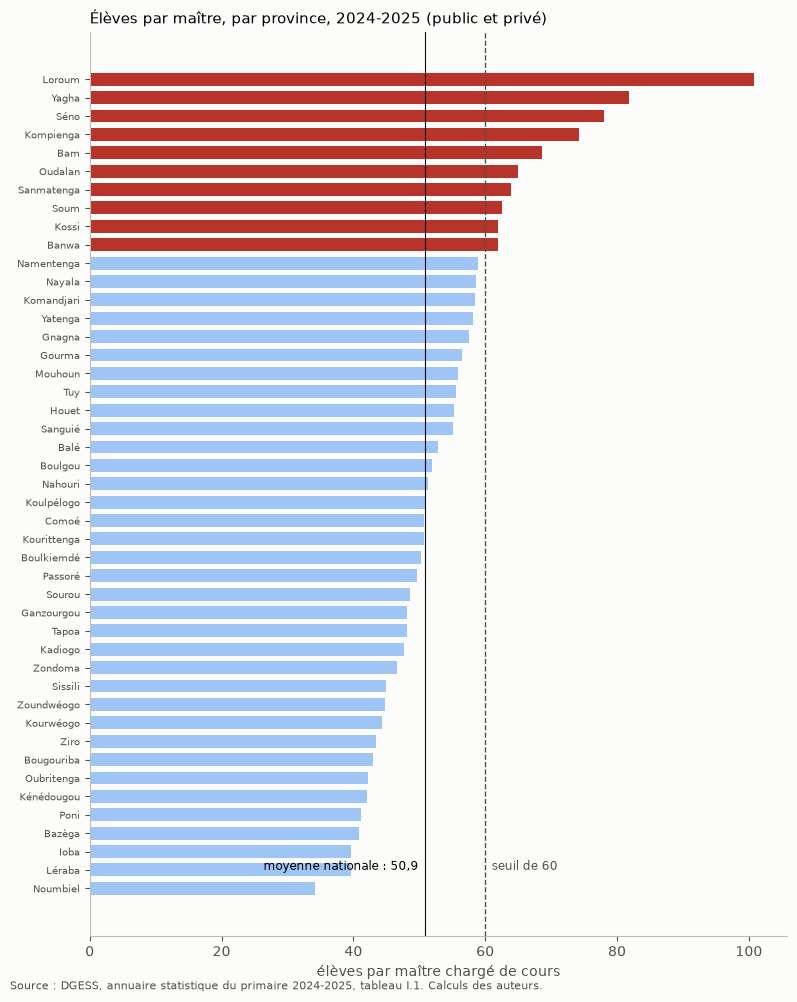

In [7]:
ordre = derniere.sort_values("eleves_par_maitre")
fig, ax = plt.subplots(figsize=(8, 10))
couleurs = ["#b8342a" if v > 60 else "#9ec5f4" for v in ordre["eleves_par_maitre"]]
ax.barh(ordre["province"], ordre["eleves_par_maitre"], color=couleurs, height=0.7)
ax.axvline(60, color="#52514e", linewidth=1, linestyle="--")
ax.text(61, 1, "seuil de 60", fontsize=8.5, color="#52514e", ha="left")
national = derniere["eleves"].sum() / derniere["maitres"].sum()
ax.axvline(national, color="#0b0b0b", linewidth=0.8)
ax.text(national - 1, 1, f"moyenne nationale : {national:.1f}".replace(".", ","), fontsize=8.5, ha="right")
ax.set_xlabel("élèves par maître chargé de cours")
ax.tick_params(axis="y", labelsize=7.5)
ax.set_title("Élèves par maître, par province, 2024-2025 (public et privé)", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Source : DGESS, annuaire statistique du primaire 2024-2025, tableau I.1. Calculs des auteurs.",
         fontsize=8, color="#52514e")
plt.tight_layout()
(PROJET / "sorties").mkdir(exist_ok=True)
fig.savefig(PROJET / "sorties" / "eleves_par_maitre_2024_2025.png", dpi=160)
plt.show()

## 4. L'état du parc de salles

Les salles aux murs en paille, en banco ou en semi-dur, et celles couvertes de paille ou sans toit, sont à remplacer en priorité.

In [8]:
etat = tables["etat_salles_province"]
e = etat[(etat["edition"] == "2024-2025") & (etat["niveau"] == "province") & (etat["statut"] == "public")].copy()
e["province"] = e["code"].map(provinces)
e.sort_values("part_salles_precaires", ascending=False)[
    ["province", "salles", "murs_paille_banco", "murs_semi_dur", "toit_paille", "toit_absent",
     "part_salles_precaires", "part_toits_precaires"]].head(10)

,province,salles,murs_paille_banco,murs_semi_dur,toit_paille,toit_absent,part_salles_precaires,part_toits_precaires
1324,Soum,141.0,23.0,20.0,29.0,0.0,0.3050,0.2128
1323,Séno,357.0,84.0,14.0,74.0,0.0,0.2745,0.2129
1325,Yagha,64.0,11.0,0.0,9.0,0.0,0.1719,0.1406
1304,Gourma,1237.0,167.0,37.0,123.0,11.0,0.1649,0.1116
1329,Noumbiel,481.0,67.0,7.0,64.0,0.0,0.1538,0.1372
1281,Sourou,312.0,42.0,5.0,38.0,0.0,0.1506,0.1250
1315,Yatenga,2109.0,214.0,53.0,168.0,8.0,0.1266,0.0915
1314,Passoré,1793.0,162.0,60.0,134.0,3.0,0.1238,0.0814
1328,Ioba,1121.0,88.0,44.0,77.0,3.0,0.1178,0.0731
1292,Sanmatenga,2100.0,147.0,98.0,188.0,15.0,0.1167,0.0981


## 5. Les effectifs par classe : base de la prévision

Chaque année est lue dans sa propre édition de l'annuaire : le premier bloc de chaque province correspond toujours à l'année de l'édition, même quand l'étiquette imprimée est absente ou fausse. Le total par classe retrouve exactement le nombre d'élèves du tableau principal (contrôle `effectifs_par_niveau_egal_eleves_tableau_principal`).

In [9]:
eff = tables["effectifs_niveau_province"]
national = eff[(eff["niveau"] == "province") & (eff["sexe"] == "T")].groupby(["annee", "classe"])["effectif"].sum().unstack()
national[["CP1", "CP2", "CE1", "CE2", "CM1", "CM2", "Total"]].astype(int)

classe,CP1,CP2,CE1,CE2,CM1,CM2,Total
annee,,,,,,,
2017-2018,671459,610931,565792,512188,448651,397039,3206060
2018-2019,642439,615227,573546,515489,468931,418152,3233784
2019-2020,636223,589185,576091,518342,470806,449700,3240347
2020-2021,663918,589728,565215,536984,478912,454979,3289736
2021-2022,642176,591782,543640,495696,464615,437037,3174946
2022-2023,586579,525984,503247,435309,404347,380078,2835544
2023-2024,711045,570514,534217,470114,411028,371022,3067940
2024-2025,772130,670695,575865,494015,441119,354272,3308096


In [10]:
tables["journal_signalements"]

,tableau,motif,fichier,page,ligne,texte
0,effectifs_niveau,libellé « Somme de » : sexe déduit de la position (G),CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,406,7,Somme de 3 897 32 3 908 282 3 875 115 3 704 321 3 062 109 2 932 499 21 378 1 358
1,effectifs_niveau,libellé « Somme de » : sexe déduit de la position (F),CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,406,8,Somme de 3 607 21 3 560 171 3 501 83 3 267 233 2 980 120 3 076 563 19 991 1 191
2,effectifs_niveau,libellé « Somme de » : sexe déduit de la position (T),CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,406,9,Somme de 7 504 53 7 468 453 7 376 198 6 971 554 6 042 229 6 008 1 062 41 369 2 549
3,effectifs_niveau,étiquette « 2019/2020 » en tête du bloc de l'édition 2020-2021 : année de l'édition retenue,CNS524_Annuaire_statistique_de_lenseignement_Primaire_2020_2021.pdf,422,10,BF5001
4,effectifs_niveau,étiquette « 2019/2020 » en tête du bloc de l'édition 2020-2021 : année de l'édition retenue,CNS524_Annuaire_statistique_de_lenseignement_Primaire_2020_2021.pdf,422,55,BF5002
...,...,...,...,...,...,...
1691,esu,4 valeurs au lieu de 7,rapport_mensuel_mars_2022_esu.pdf,10,31,YAGHA 4 270 381 651
1692,esu,4 valeurs au lieu de 7,rapport_mensuel_mars_2022_esu.pdf,10,33,BOUGOURIBA 31 81 119 200
1693,esu,4 valeurs au lieu de 7,rapport_mensuel_mars_2022_esu.pdf,10,34,IOBA 16 20 9 29
1694,esu,4 valeurs au lieu de 7,rapport_mensuel_mars_2022_esu.pdf,10,35,SUD-OUEST NOUMBIEL 14 57 64 121


## 6. Les enseignants

Le tableau des enseignants donne, par province, sexe et statut, les corps, les fonctions et le type de classe tenue. Jusqu'en 2022-2023, l'annuaire compte cinq corps ; les corps P.C.E. et P.E. apparaissent ensuite et restent vides auparavant. Les enseignants tenant une classe retrouvent exactement les maîtres chargés de cours du tableau principal.

In [11]:
ens = tables["enseignants_province"]
pub = ens[(ens["niveau"] == "province") & (ens["sexe"] == "T") & (ens["statut"] == "public")]
pub.groupby("edition")[["enseignants", "tenant_classe", "directeurs", "suppleants", "classes_multigrades",
                        "classes_double_flux"]].sum().astype(int)

,enseignants,tenant_classe,directeurs,suppleants,classes_multigrades,classes_double_flux
edition,,,,,,
2017-2018,62999,51081,11595,9326,2745,0
2018-2019,63369,50191,11053,10342,1853,0
2019-2020,67303,48712,10630,12763,1402,0
2020-2021,71597,48749,10537,14849,977,0
2021-2022,66351,45933,9868,12836,795,0
2022-2023,61645,38988,8292,14073,506,0
2023-2024,69020,42446,9049,16168,513,0
2024-2025,69578,44623,9503,14229,645,0


## 7. La population d'âge scolaire jusqu'en 2035

Les projections de l'INSD donnent, par région et par province, la population par groupe d'âges et par sexe de 2020 à 2035. Le groupe 6-11 ans correspond à l'âge officiel du primaire. Deux blocs aux colonnes décalées dans la source sont interpolés entre les années voisines (colonne `valeur_interpolee`).

In [12]:
pop = tables["population_projetee"]
age = pop[(pop["groupe_age"] == "6-11") & (pop["niveau"] == "province")].groupby("annee")["ensemble"].sum()
eleves = eff[(eff["niveau"] == "province") & (eff["sexe"] == "T") & (eff["classe"] == "Total")].groupby("annee")["effectif"].sum()
eleves.index = eleves.index.str[:4].astype(int)
demande = pd.DataFrame({"enfants_6_11_ans": age, "eleves_inscrits": eleves})
demande["rapport_eleves_population"] = (demande["eleves_inscrits"] / demande["enfants_6_11_ans"]).round(3)
demande.loc[[2017, 2020, 2022, 2024, 2025, 2030, 2035]].dropna(how="all")

,enfants_6_11_ans,eleves_inscrits,rapport_eleves_population
annee,,,
2017,NaN,3206060.0,NaN
2020,3679719.0,3289736.0,0.894
2022,3948021.0,2835544.0,0.718
2024,4203855.0,3308096.0,0.787
2025,4328008.0,NaN,NaN
2030,4664547.0,NaN,NaN
2035,4845538.0,NaN,NaN


Le rapport entre élèves inscrits (année scolaire commençant l'année indiquée) et enfants de 6 à 11 ans est une approximation du taux brut de scolarisation. La population d'âge scolaire croît de plus de 600 000 enfants entre 2024 et 2035 : c'est la demande à laquelle l'offre d'enseignants et de salles devra répondre.

## 8. L'échelle de la commune

Les annuaires régionaux de l'INSD (10 régions sur 13) donnent, par commune et sur une dizaine d'années, les écoles, les salles, les salles sous paillote, les élèves et les enseignants. Chaque tableau est reconnu par les mots de son titre, et chaque commune parmi celles de la région du fichier. Quand toutes les communes d'une province sont lues, la somme de leurs élèves retrouve les élèves publiés par la DGESS pour la province.

In [13]:
com = tables["communes_primaire"]
com.groupby(["region_code_ancien", "indicateur"])["commune_code"].nunique().unstack().fillna(0).astype(int)

indicateur,ecoles,eleves_par_sexe,eleves_par_statut,enseignants_par_sexe,enseignants_par_statut,salles,salles_paillote
region_code_ancien,,,,,,,
BF13,7,7,7,0,7,7,7
BF46,45,45,45,45,45,45,0
BF47,17,17,17,17,17,17,17
BF50,36,36,36,35,0,36,0
BF51,11,18,18,0,0,18,0
BF53,29,29,29,29,29,29,24
BF54,28,28,28,28,28,28,0
BF55,17,17,17,0,17,17,0
BF56,26,18,0,24,14,20,0


In [14]:
noms = tables["territoire_commune"].set_index("commune_code")["commune"]
paillotes = com[(com["indicateur"] == "salles_paillote") & (com["modalite"] == "ensemble") & (com["annee"] == com["annee"].max())]
paillotes.assign(commune=paillotes["commune_code"].map(noms)).nlargest(10, "valeur")[["commune", "region_code_ancien", "annee", "valeur"]]

,commune,region_code_ancien,annee,valeur
22278,Sideradougou,BF47,2023-2024,140.0
35796,Batie,BF57,2023-2024,55.0
35846,Loropeni,BF57,2023-2024,46.0
22320,Tiefora,BF47,2023-2024,38.0
22194,Mangodara,BF47,2023-2024,34.0
35816,Gaoua,BF57,2023-2024,32.0
35756,Iolonioro,BF57,2023-2024,31.0
35761,Dano,BF57,2023-2024,29.0
35766,Dissihn,BF57,2023-2024,27.0
22152,Banfora,BF47,2023-2024,25.0


## 9. Le contexte sécuritaire

Les rapports du ST-ESU donnent les écoles primaires fermées, rouvertes et délocalisées, avec les élèves et les enseignants touchés. Un tableau n'est jugé fiable que si la somme de ses provinces retrouve le total primaire publié à 5 % près ; les rapports lus par reconnaissance de caractères n'y parviennent pas. Les déplacés internes sont rattachés aux communes par leur P-code uniquement.

In [15]:
esu = tables["ecoles_crise_province"]
esu[esu["tableau_fiable"]].groupby(["mois", "situation"])[["etablissements", "eleves", "enseignants"]].sum().astype(int)

etablissements  eleves  enseignants
mois       situation                                        
2021-11-30 fermees                 2592  360315        11146
           rouvertes                165   34764          859
2021-12-31 delocalisees              12    1980           70
           fermees                 2875  432111        12968
           rouvertes                171   31090          824
2022-01    delocalisees              35    6637          277
           fermees                 2983  442009        13406
           rouvertes                141   30044          680
2022-03    delocalisees              64   17558          460
           fermees                 3206  492229        14768
           rouvertes                174   35301          897
2022-04    delocalisees              40    7196          279
           fermees                 3623  579970        17107
           rouvertes                129   25752          646
2022-05    delocalisees              20    4136          149
           fermees                 3725  600723        17673
           rouvertes                135   27232          678
2023-10    fermees                   96   16218          451

In [16]:
dep = tables["deplaces_commune"]
serie = dep.groupby("date_situation").agg(deplaces=("deplaces", "sum"), communes=("commune_code", "nunique"))
serie.iloc[[0, 12, 24, 36, -1]].astype(int)

,deplaces,communes
date_situation,,
2019-01-27,81964,37
2020-02-14,765517,165
2021-03-31,1147699,269
2022-03-31,1849298,274
2023-03-31,2062534,303


La situation du 30 avril 2022 (1,52 million) est nettement inférieure à celle du 28 avril (1,90 million) : l'écart est présent dans le fichier source lui-même, avec P-codes et dates, et il est conservé tel quel.

## 10. Métadonnées : dictionnaire des variables

In [17]:
tables["_variables"][tables["_variables"]["table"] == "offre_province"]

,table,variable,type,unite,description
23,offre_province,edition,texte,,Année scolaire de l'annuaire dont provient la valeur
24,offre_province,code,texte,,"Code de l'entité dans l'ancien découpage (province, région, ou BF pour le pays)"
25,offre_province,niveau,texte,,"Niveau géographique de l'entité : province, region ou pays"
26,offre_province,statut,texte,,"Statut des écoles : public, prive ou total"
27,offre_province,ecoles,décimal,écoles,Nombre d'écoles primaires
28,offre_province,salles,décimal,salles,Nombre de salles de classe
29,offre_province,groupes_pedagogiques,décimal,groupes,Nombre de groupes pédagogiques (classes constituées)
30,offre_province,maitres,décimal,maîtres,Nombre de maîtres chargés de cours
31,offre_province,eleves,décimal,élèves,Nombre d'élèves inscrits
32,offre_province,eleves_par_maitre_publie,décimal,élèves par maître,"Élèves par maître, tel que publié par la DGESS"


## 11. Dépôt au format du challenge

In [18]:
depot = deposer_nettoyage(version=1)
depot[["fichier", "role"]]

,fichier,role
0,EXX_02-nettoyage_D3_architect_base-boussole-sqlite_v1.db,architect
1,EXX_02-nettoyage_D3_architect_metadonnees-tables_v1.csv,architect
2,EXX_02-nettoyage_D3_architect_metadonnees-dictionnaire-variables_v1.csv,architect
3,EXX_02-nettoyage_D3_engineer_territoires-communes-deux-decoupages_v1.csv,engineer
4,EXX_02-nettoyage_D3_engineer_territoires-provinces-ancien-decoupage_v1.csv,engineer
5,EXX_02-nettoyage_D3_engineer_territoires-regions-ancien-decoupage_v1.csv,engineer
6,EXX_02-nettoyage_D3_engineer_offre-ecoles-salles-maitres-eleves-province-2017-2025_v1.csv,engineer
7,EXX_02-nettoyage_D3_engineer_etat-murs-toitures-salles-province-2017-2025_v1.csv,engineer
8,EXX_02-nettoyage_D3_engineer_effectifs-redoublants-classe-sexe-province-2017-2025_v1.csv,engineer
9,EXX_02-nettoyage_D3_engineer_enseignants-corps-fonction-province-2017-2025_v1.csv,engineer


## Suite

Le nettoyage est complet pour les sources retenues au défi 3. L'étape 03 réunira ces tables dans une table d'analyse unique, par province et par année, pour la prévision et l'optimisation.